# Figure 1, Panel B

MA plots for BRM014 titration and timecourse ATAC-seq DAR analysis.Inputs are processed ATAC-seq count matrices and peak annotations.

*Output: panel_b.pdf*

# Setup

In [19]:
#load required packages
library(tidyverse)
library(edgeR)
library(ggrastr)
library(gridExtra)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/Figure1/PanelB/Panel_B.ipynb")

sessionInfo()

# Differential Accessibility Region (DAR) Analysis with Custom Normalization
#
# This function performs differential accessibility analysis using edgeR,
# incorporating custom normalization based on user-supplied effective library sizes 
# The specific use case is for normalizing ATAC-seq using counts from promoter regions of genes that are invariantly expressed in control and BAF-inhibited samples.
#
# Inputs are:
#     data,  A matrix of raw counts (peaks x samples).
#     coldata, A data frame containing sample metadata. Must include:
#      `Condition`: Factor or character vector indicating experimental groups (e.g., control, treatment).
#      `sizes`: Numeric vector of effective library sizes (i.e., sum of counts at invariant promoters)
#
# This function returns a data frame with differential test results for each region, including logFC, p-values, and FDR
# As well as a classification of each element as gaining ("up"), losing ("down"), or not changing ("nc") in accessibility
# Based on FDR and logFC cutoffs of 0.05 and log2(1.5), respectively

dar <- function(data, coldata) {
    library(edgeR)
  
  # Create DGEList object with counts and group information
    dge <- DGEList(counts = data, group = coldata$Condition)
  
  # Override default library size with effective library sizes from control regions
    dge$samples$lib.size <- coldata$sizes
  
  # Set normalization factors to 1 (i.e., use lib.size as-is with no further scaling)
    dge$samples$norm.factors <- rep(1, nrow(coldata))
  
  # Create design matrix for comparison (model without intercept, group-specific columns)
    design <- model.matrix(~0 + group, data = dge$samples)
    colnames(design) <- levels(dge$samples$group)  # optional: label columns by condition names
  
  # Estimate dispersion 
    dge <- estimateDisp(dge, design)
  
  # Fit generalized linear model (GLM) 
    dge_fit <- glmQLFit(dge, design)
  
  # Conduct differential test (treatment vs control)
    diff <- glmQLFTest(dge_fit, contrast = c(1, -1))
  
  # Return all regions without sorting; include logFC, p-value, FDR, etc.
    res <- topTags(diff, n = Inf, sort.by = "none")$table 
  # Add column categorizing peaks as gaining, losing, or not changing accessibility
    res <- res %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(2) ~ "up",
                                       FDR < 0.05 & logFC < -log2(2) ~ "down",
                                       TRUE ~ "nc"))
  return(res)
}

# This function implements the dar() function separately for TSS-distal and TSS-proximal peaks. 
# In addition to the data and coldata params required by dar(), this function additionall requires
# a 'rowdata' object (should contain minimally genomic coordinates and TSS proximity for each row)

# This function returns a list object where the first element is the table of results from DAR analysis, 
# And the second is a reformatted rowdata object (rows reordered so that they match the results table)

dar_splitTSS <- function(data, coldata, rowdata){ 
    #Use row metadata to split counts matrix into TSS-proximal and dista
    #Run DAR analysis separately on each
    res_tss <- dar(data=data[rowdata$TSS==TRUE,], coldata)
    res_nontss <- dar(data=data[rowdata$TSS==FALSE,], coldata)

    #combine TSS and nonTSS DAR results
    res <- rbind(res_tss, res_nontss)
    #reorder rowdata
    rowdata <- rbind(rowdata[rowdata$TSS==TRUE,], rowdata[rowdata$TSS==FALSE,])
    return(list("results"=res, "row_meta"=rowdata))
}



#Function to generate MA plots with fixed axis dimensions, annotated with # of regions gaining, losing, or not significantly changing accessibility
MAplot <- function(res) { #input results table from dar() or dar_split_tss()
    
    plot <- res %>% ggplot(aes(x=logCPM, y= logFC, color=change)) + 
                        theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15, color="black")) +  #set aesthetics
                        geom_hline(yintercept=0,linetype=2) + 
                        rasterize(geom_point(size=.25, show.legend=FALSE), dpi=300) + 
                        #color points by effect of BAFinh
                        scale_color_manual(values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2], "nc" = "grey80"),
                                           labels = c("nc" = "Not significant", "up" = "Gained accessibility", "down" = "Lost accessibility")) +
                        labs(
                            #annotate with # of DARs (and # of n.s. regions)
                            subtitle=paste("down:", nrow(res[res$change=="down",]), "n.s.:", nrow(res[res$change=="nc",]), "up:", nrow(res[res$change=="up",])),
                            x = expression(log[2] ~ "CPM"),
                            y = expression(log[2] ~ "fold change in accessibility")) + 
                        scale_y_continuous(breaks=c(-9, -6, -3, 0,3), limits=c(-9,3)) +
                        scale_x_continuous(limits=c(0,10), breaks=c(0,5,10)) + 
                        coord_fixed(ratio=.8333)
    return(plot)
}

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 gridExtra_2.3     
 [5] ggrastr_1.0.2      edgeR_3.40.2       limma_3.54.2       lubridate_1.9.4   
 [9] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
[13] readr_2.1.5        tidyr_1.3.1        tibble_3

# Defining inputs for BRM014 titration and timecourse experiments

In [5]:
## row metadata
row_meta <- read.delim(
    here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
    sep = "\t"
)

## ----------------------------
## BRM014 titration (6h)
## ----------------------------

# counts matrix
countmat_titration <- read.delim(
    here("inputs", "countmat", "titration_6h", "titration_countmat.tsv"),
    header = FALSE,
    sep = "\t"
)

# subsetting to only include counts data (excluding genomic coordinates)
counts_titration <- countmat_titration[, 5:17]

# control matrix (invariant promoters)
control_titration <- read.delim(
    here("inputs", "countmat", "titration_6h", "titration_countmat_control.tsv"),
    header = FALSE,
    sep = "\t"
)

# library sizes for normalization
lib_sizes_titration <- colSums(control_titration[, 5:17])

# column metadata
col_meta_titration <- read.delim(
    here("inputs", "countmat", "titration_6h", "column_metadata.txt"),
    sep = "\t"
) %>%
    mutate(
        sizes = lib_sizes_titration,
        var   = Dose
  )

## ----------------------------
## BRM014 timecourse
## ----------------------------

# counts matrix
countmat_timecourse <- read.delim(
    here("inputs", "countmat", "brm10uM_timecourse", "timecourse_countmat.tsv"),
    header = FALSE,
    sep = "\t"
)

# subsetting to only include counts data (excluding genomic coordinates)
counts_timecourse <- countmat_timecourse[, 5:30]

# control matrix (invariant promoters)
control_timecourse <- read.delim(
    here("inputs", "countmat", "brm10uM_timecourse", "timecourse_control_countmat.tsv"),
    header = FALSE,
    sep = "\t"
)

# library sizes for normalization
lib_sizes_timecourse <- colSums(control_timecourse[, 5:30])

# column metadata
col_meta_timecourse <- read.delim(
    here("inputs", "countmat", "brm10uM_timecourse", "column_metadata.txt"),
    sep = "\t"
) %>%
    mutate(
        sizes = lib_sizes_timecourse,
        var   = Time
  )


#DAR results for all comparisons used in this 

# Differential Accessibility Region (DAR) Analysis with Custom Normalization

In [12]:
## Run Differential accessibility analysis

#BAFinh dose series

#10nM
dar_0.01 <- dar_splitTSS(
    data    = counts_titration[, col_meta_titration$Dose %in% c(0, 0.01)],
    coldata = col_meta_titration[col_meta_titration$Dose %in% c(0, 0.01), ],
    row_meta
)

#100nM
dar_0.1 <- dar_splitTSS(
    data    = counts_titration[, col_meta_titration$Dose %in% c(0, 0.1)],
    coldata = col_meta_titration[col_meta_titration$Dose %in% c(0, 0.1), ],
    row_meta
)

#1uM
dar_1 <- dar_splitTSS(
    data    = counts_titration[, col_meta_titration$Dose %in% c(0, 1)],
    coldata = col_meta_titration[col_meta_titration$Dose %in% c(0, 1), ],
    row_meta
)

#10uM
dar_10 <- dar_splitTSS(
    data    = counts_titration[, col_meta_titration$Dose %in% c(0, 10)],
    coldata = col_meta_titration[col_meta_titration$Dose %in% c(0, 10), ],
    row_meta
)

# BAFinh timecourse
#0.5h
dar_0.5h <- dar_splitTSS(
    data    = counts_timecourse[, col_meta_timecourse$Time %in% c(0, 0.5)],
    coldata = col_meta_timecourse[col_meta_timecourse$Time %in% c(0, 0.5), ],
    row_meta
)

#1h
dar_1h <- dar_splitTSS(
    data    = counts_timecourse[, col_meta_timecourse$Time %in% c(0, 1)],
    coldata = col_meta_timecourse[col_meta_timecourse$Time %in% c(0, 1), ],
    row_meta
)

#2h
dar_2h <- dar_splitTSS(
    data    = counts_timecourse[, col_meta_timecourse$Time %in% c(0, 2)],
    coldata = col_meta_timecourse[col_meta_timecourse$Time %in% c(0, 2), ],
    row_meta
)

#6h
dar_6h <- dar_splitTSS(
    data    = counts_timecourse[, col_meta_timecourse$Time %in% c(0, 6)],
    coldata = col_meta_timecourse[col_meta_timecourse$Time %in% c(0, 6), ],
    row_meta
)

#24h
dar_24h <- dar_splitTSS(
    data    = counts_timecourse[, col_meta_timecourse$Time %in% c(0, 24)],
    coldata = col_meta_timecourse[col_meta_timecourse$Time %in% c(0, 24), ],
    row_meta
)

# Generate MA plots

In [20]:
#BAFinh dose series MA plots - plots by dose
p1 <- MAplot(dar_0.01$results)
p2 <- MAplot(dar_0.1$results)
p3 <- MAplot(dar_1$results)
p4 <- MAplot(dar_10$results)

# compilation of MA plots for all doses
titration_ma <- p1 | p2 | p3 | p4 

In [21]:
#BAFinh timecourse series MA plots
p1 <- MAplot(dar_0.5h$results)
p2 <- MAplot(dar_1h$results)
p3 <- MAplot(dar_2h$results)
p4 <- MAplot(dar_6h$results)
p5 <- MAplot(dar_24h$results)

# compilation of MA plots for all timepoints
timecourse_ma <- p1 | p2 | p3 | p4 | p5 

# Output figure panel

Warning message:
“Removed 33 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 11 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()

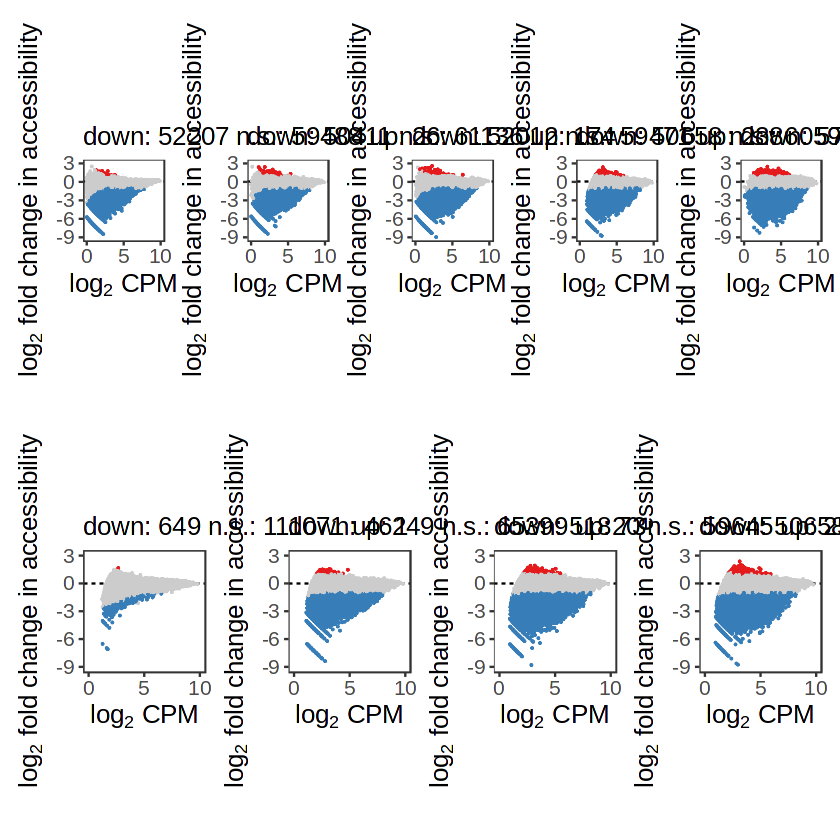

In [22]:
timecourse_ma / titration_ma
ggsave("panel_b.pdf", width=15)